# Main theoretical figures: kernel gradient flow and ridge regression

Run all cells, in order, from the repository directory. This standalone notebook **recomputes Figures 2–5 from the analytical equations**; it does not read simulation records, checkpoints, CSV files, or previously generated arrays. It requires only Python, NumPy, SciPy, Matplotlib, and threadpoolctl. Figures are saved in `Figures/`, using the filenames included by `main_arxiv.tex`.

The sample ratio is $\alpha=n/d$, the kernel shift is $b=\cot^2\gamma$, the reduced time is $\tau=\mu_1^2t$, and the reduced ridge parameter is $\ell=\lambda/\mu_1^2$. We use $a=(1-\varepsilon)\sqrt{2/\pi}$ and $b_c=a^{-2}-1$. Spectral averages include the Marchenko–Pastur atom at zero where required. The training square loss uses the paper's $1/(2n)$ convention.

Numerical checks below compare spectral moments and analytical endpoints, refine quadrature and time minimization, and independently recompute the small Figure 5 differences using Gauss–Legendre quadrature and tighter root tolerances. The first figure is the slowest because it optimizes the stopping time over an entire phase diagram.


In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
from functools import lru_cache
import json, math, platform
import numpy as np
import scipy
from scipy.optimize import brentq, minimize_scalar
from scipy.special import erfc, roots_legendre
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import ScalarFormatter, MaxNLocator, FixedLocator, FuncFormatter
from matplotlib.colors import Normalize
from threadpoolctl import threadpool_limits
try:
    from IPython.display import display, Image
except ImportError:
    def Image(filename): return str(filename)
    def display(value): print(value)

OUT = Path("Figures")
OUT.mkdir(parents=True, exist_ok=True)
PLOT_STYLE = {
    "font.family": "serif", "font.size": 18, "mathtext.fontset": "dejavuserif",
    "text.usetex": False, "axes.labelsize": 21, "axes.titlesize": 17,
    "xtick.labelsize": 17, "ytick.labelsize": 17, "legend.fontsize": 14,
    "axes.linewidth": 1.0, "pdf.fonttype": 42, "ps.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
}
COLORS = ("#0072B2", "#D55E00", "#009E73")
NQUAD = 1600

def save_figure(fig, stem):
    for extension in ("pdf", "png"):
        path = OUT / f"{stem}.{extension}"
        fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
        print(f"Saved: {path}")
    plt.close(fig)

def save_json(name, value):
    
    def clean(x):
        if isinstance(x, dict): return {k: clean(v) for k, v in x.items()}
        if isinstance(x, (list, tuple)): return [clean(v) for v in x]
        if isinstance(x, np.ndarray): return clean(x.tolist())
        if isinstance(x, (np.integer,)): return int(x)
        if isinstance(x, (np.floating, float)):
            return "infinity" if np.isposinf(x) else float(x)
        return x
    (OUT/name).write_text(json.dumps(clean(value), indent=2)+"\n")

print("Python", platform.python_version(), "NumPy", np.__version__,
      "SciPy", scipy.__version__, "Matplotlib", matplotlib.__version__)
print("All PDFs will be saved in", OUT)

# Keep BLAS parallelism modest; all calculations below remain deterministic.
_thread_limit = threadpool_limits(limits=1)


Python 3.12.15 NumPy 2.5.4 SciPy 1.18.1 Matplotlib 3.11.2
All PDFs will be saved in Figures


## Figure 2: cost of training to interpolation

Here $\gamma=\pi/5$, $\delta_0=0$, and $\lambda=0$. At each $(\alpha,\varepsilon)$ we compare the converged error with the minimum along the gradient-flow trajectory. The exact boundary is $\varepsilon_c=1-\sqrt{\pi/2}\sin\gamma$.


In [2]:
from pathlib import Path
from functools import lru_cache
import json
import platform
import numpy as np
import scipy
from scipy.special import roots_legendre
from scipy.optimize import minimize_scalar
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import FixedLocator, FuncFormatter

OUT = Path('Figures')
OUT.mkdir(parents=True, exist_ok=True)
GAMMA = np.pi / 5
DELTA0 = 0.0
RIDGE = 0.0
EPSILON_C = 1.0 - np.sqrt(np.pi / 2.0) * np.sin(GAMMA)
assert 0 < EPSILON_C < 0.9
assert DELTA0 == 0.0 and RIDGE == 0.0  
ALPHAS = np.unique(np.r_[np.geomspace(0.1, 20.0, 151), 1.0])
EPSILONS = np.unique(np.r_[np.linspace(0.0, 0.9, 181), EPSILON_C])
N_QUAD = 600
N_TIME = 700
print(f'gamma/pi={GAMMA/np.pi:.6f}; epsilon_c={EPSILON_C:.10f}')
print(f'{len(ALPHAS)} sample ratios x {len(EPSILONS)} noise levels')
print('Outputs:', OUT)


gamma/pi=0.200000; epsilon_c=0.2633204336
152 sample ratios x 182 noise levels
Outputs: Figures


In [3]:
@lru_cache(maxsize=24)
def legendre_rule(order):
    return roots_legendre(int(order))

@lru_cache(maxsize=400)
def mp_quadrature(alpha, order=N_QUAD):
    alpha = float(alpha)
    if alpha <= 0:
        raise ValueError('alpha must be positive')
    nodes, weights = legendre_rule(order)
    theta = (nodes + 1.0) * np.pi / 2.0
    s = (np.sqrt(alpha)-1.0)**2 + 4*np.sqrt(alpha)*np.sin(theta/2.0)**2
    weights = weights * np.sin(theta)**2 / s
    return s, weights

def error_from_moments(alpha, epsilon, first, second, inverse_second, init=0.):
    a = (1.0-np.asarray(epsilon))*np.sqrt(2.0/np.pi)
    denominator = a*a*second + (1.0-a*a)*inverse_second + init
    correlation = a*np.sqrt(alpha)*first/np.sqrt(denominator)
    if np.any(correlation < -1e-10) or np.any(correlation > 1+1e-10):
        raise ArithmeticError('Correlation outside its physical range')
    return np.arccos(np.clip(correlation, -1., 1.))/np.pi

def curve_errors(alpha, epsilon, times, gamma=GAMMA, delta0=DELTA0,
                 order=N_QUAD):
    s, weights = mp_quadrature(float(alpha), int(order))
    spectral_shift = 1.0/np.tan(gamma)**2
    times = np.atleast_1d(np.asarray(times, dtype=float))
    if np.any(times <= 0) or np.any(np.isnan(times)):
        raise ValueError('Use strictly positive times, optionally including infinity')
    rate = s + spectral_shift
    exponent = times[:, None]*rate
    residual = np.exp(-exponent)
    response = (s/rate)*(-np.expm1(-exponent))
    return error_from_moments(alpha, epsilon,
        response@weights, response**2@weights,
        response**2@(weights/s), delta0*(residual**2@(weights*s)))

def endpoint_error_exact(alpha, epsilon, gamma=GAMMA):
    
    z = 1.0/np.tan(gamma)**2
    d = z+1.0-alpha
    discriminant = np.sqrt(d*d+4*alpha*z)
    M = 2.0/(discriminant+d) if d >= 0 else (discriminant-d)/(2*alpha*z)
    M2 = (alpha*M*M+M)/discriminant  
    return error_from_moments(alpha, epsilon, 1-z*M,
                             1-2*z*M+z*z*M2, M-z*M2)

def initial_right_limit(alpha, epsilon, delta0=DELTA0):
    
    if delta0 > 0:
        return 0.5
    a = (1.0-np.asarray(epsilon))*np.sqrt(2.0/np.pi)
    return np.arccos(a*np.sqrt(alpha/(1+a*a*alpha)))/np.pi

def search_time_grid(alpha, gamma=GAMMA, count=N_TIME, upper_factor=96.):
    shift = 1.0/np.tan(gamma)**2
    lower_rate = (np.sqrt(alpha)-1.)**2+shift
    upper_rate = (np.sqrt(alpha)+1.)**2+shift
    return np.geomspace(1e-7/upper_rate, upper_factor/lower_rate, int(count))

def best_error(alpha, epsilon, gamma=GAMMA, delta0=DELTA0,
               order=N_QUAD, count=N_TIME, upper_factor=96.,
               precomputed=None):
    endpoint = float(endpoint_error_exact(alpha, epsilon, gamma))
    critical_noise = 1.0-np.sqrt(np.pi/2.)*np.sin(gamma)
    if epsilon <= critical_noise:
        return endpoint, np.inf, endpoint, 0  
    times = search_time_grid(alpha, gamma, count, upper_factor)
    values = (curve_errors(alpha, epsilon, times, gamma, delta0, order)
              if precomputed is None else np.asarray(precomputed))
    
    indices = np.flatnonzero((values[1:-1] < values[:-2]) &
                             (values[1:-1] <= values[2:]))+1
    indices = indices[values[indices] < endpoint-5e-15]
    candidates = [(endpoint, np.nan),
                  (float(initial_right_limit(alpha, epsilon, delta0)), 0.)]
    for index in indices:
        result = minimize_scalar(
            lambda logtime: float(curve_errors(alpha, epsilon, [np.exp(logtime)],
                                               gamma, delta0, order)[0]),
            bounds=(np.log(times[index-1]), np.log(times[index+1])),
            method='bounded', options={'xatol': 2e-10})
        if not result.success:
            raise ArithmeticError('Time minimization failed')
        candidates.append((float(result.fun), float(np.exp(result.x))))
    error, time = min(candidates, key=lambda item: item[0])
    
    
    return error, time, endpoint, len(indices)


In [4]:
def build_phase_map():
    shape = (len(EPSILONS), len(ALPHAS))
    optimal = np.empty(shape)
    endpoint = np.empty(shape)
    stopping_time = np.empty(shape)
    candidates_count = np.zeros(shape, dtype=int)
    for column, alpha in enumerate(ALPHAS):
        s, weights = mp_quadrature(float(alpha), N_QUAD)
        shift = 1.0/np.tan(GAMMA)**2
        times = search_time_grid(alpha)
        residual = np.exp(-times[:, None]*(s+shift))
        response = s/(s+shift)*(-np.expm1(-times[:, None]*(s+shift)))
        a2 = ((1-EPSILONS)*np.sqrt(2/np.pi))**2
        p = response@weights
        q1 = response**2@weights
        q2 = response**2@(weights/s)
        qi = DELTA0*(residual**2@(weights*s))
        correlation = np.sqrt(alpha*a2)[None, :]*p[:, None]/np.sqrt(
            q1[:, None]*a2[None, :] + q2[:, None]*(1-a2)[None, :] + qi[:, None])
        errors = np.arccos(np.clip(correlation, -1, 1))/np.pi
        for row, epsilon in enumerate(EPSILONS):
            opt, tau, end, n_candidates = best_error(
                float(alpha), float(epsilon), precomputed=errors[:, row])
            optimal[row, column], stopping_time[row, column] = opt, tau
            endpoint[row, column], candidates_count[row, column] = end, n_candidates
        if (column+1) % 20 == 0 or column+1 == len(ALPHAS):
            print(f'Computed {column+1}/{len(ALPHAS)} sample ratios', flush=True)
    gap = endpoint-optimal
    if np.any(gap < -1e-12):
        raise ArithmeticError('Stopping benefit must be nonnegative')
    return dict(optimal=optimal, endpoint=endpoint, tau_es=stopping_time,
                delta_stop=np.maximum(gap, 0.), candidate_count=candidates_count)

phase = build_phase_map()
maximum_index = np.unravel_index(np.argmax(phase['delta_stop']), phase['delta_stop'].shape)
peak_epsilon, peak_alpha = EPSILONS[maximum_index[0]], ALPHAS[maximum_index[1]]
print(f"Largest sampled benefit: {100*phase['delta_stop'][maximum_index]:.6f} percentage points")
print(f'At alpha={peak_alpha:.6f}, epsilon={peak_epsilon:.6f}')


Computed 20/152 sample ratios
Computed 40/152 sample ratios
Computed 60/152 sample ratios
Computed 80/152 sample ratios
Computed 100/152 sample ratios
Computed 120/152 sample ratios
Computed 140/152 sample ratios
Computed 152/152 sample ratios
Largest sampled benefit: 0.423902 percentage points
At alpha=4.080572, epsilon=0.740000


In [5]:
def validate_phase_map(phase):
    records = []
    maximum_endpoint_difference = 0.
    maximum_moment_difference = 0.
    for alpha in ALPHAS:
        s, weights = mp_quadrature(float(alpha), N_QUAD)
        moment_error = max(abs(weights.sum()-min(1.,1./alpha)),
                           abs(s@weights-1.), abs(s*s@weights-(1.+alpha)))
        maximum_moment_difference = max(maximum_moment_difference, moment_error)
        for epsilon in (0., EPSILON_C, .5, .9):
            numerical = curve_errors(alpha, epsilon, [np.inf])[0]
            exact = endpoint_error_exact(alpha, epsilon)
            maximum_endpoint_difference = max(maximum_endpoint_difference, abs(numerical-exact))
    assert maximum_moment_difference < 2e-8
    assert maximum_endpoint_difference < 2e-9
    below = EPSILONS <= EPSILON_C
    assert np.all(phase['delta_stop'][below] == 0.)
    assert np.all(np.isinf(phase['tau_es'][below]))
    above_times = phase['tau_es'][~below]
    assert not np.any(np.isinf(above_times))
    
    cases = [(a,e) for a in (.1,.5,1.,2.,5.,20.)
             for e in (EPSILON_C+1e-4,.3,.6,.9)]
    cases += [(float(peak_alpha),float(peak_epsilon)), (1.5,.1)]
    largest_refinement_difference = 0.
    for alpha, epsilon in cases:
        base, _, _, _ = best_error(alpha, epsilon)
        refined, tau, end, _ = best_error(alpha, epsilon, order=2400,
                                          count=2800, upper_factor=384.)
        discrepancy = abs(base-refined)
        largest_refinement_difference = max(largest_refinement_difference, discrepancy)
        assert discrepancy < 2e-8
        independent_times = search_time_grid(alpha, count=3101, upper_factor=384.)
        independent = curve_errors(alpha, epsilon, independent_times, order=1600)
        assert independent.min() >= refined-2e-8
        assert refined <= end+2e-9
        
        critical_angle = np.arcsin(np.sqrt(2/np.pi)*(1-epsilon))
        bound = endpoint_error_exact(alpha, epsilon, critical_angle)
        assert refined >= bound-2e-8
        if np.isfinite(tau) and tau > 0 and end-refined > 1e-10:
            stencil = curve_errors(alpha,epsilon,tau*np.exp(np.array([-1e-3,0,1e-3])),order=2400)
            derivative = (stencil[2]-stencil[0])/(2e-3)
            assert abs(derivative) < 2e-7
        records.append(dict(alpha=float(alpha), epsilon=float(epsilon),
                            refined_gap_pp=float(100*(end-refined)),
                            refinement_error=float(discrepancy)))
    for alpha in (.1,1.,2.,20.):
        s,w=mp_quadrature(alpha,2400)
        shift=1/np.tan(GAMMA)**2
        critical_bound=np.arccos(np.sqrt(alpha*((s/(s+shift))@w)))/np.pi
        assert abs(critical_bound-endpoint_error_exact(alpha,EPSILON_C)) < 2e-9
    checks=dict(mp_moment_max_abs_error=float(maximum_moment_difference),
                endpoint_max_abs_error=float(maximum_endpoint_difference),
                refinement_max_abs_error=float(largest_refinement_difference),
                validation_cases=records)
    print('All numerical checks passed.')
    print('Largest refinement difference in error:', largest_refinement_difference)
    return checks

checks = validate_phase_map(phase)


All numerical checks passed.
Largest refinement difference in error: 3.9948599983574695e-13


Saved PDF: Figures/Figure2_phase_diagram.pdf
Saved PNG: Figures/Figure2_phase_diagram.png
Saved arrays and numerical-check protocol.


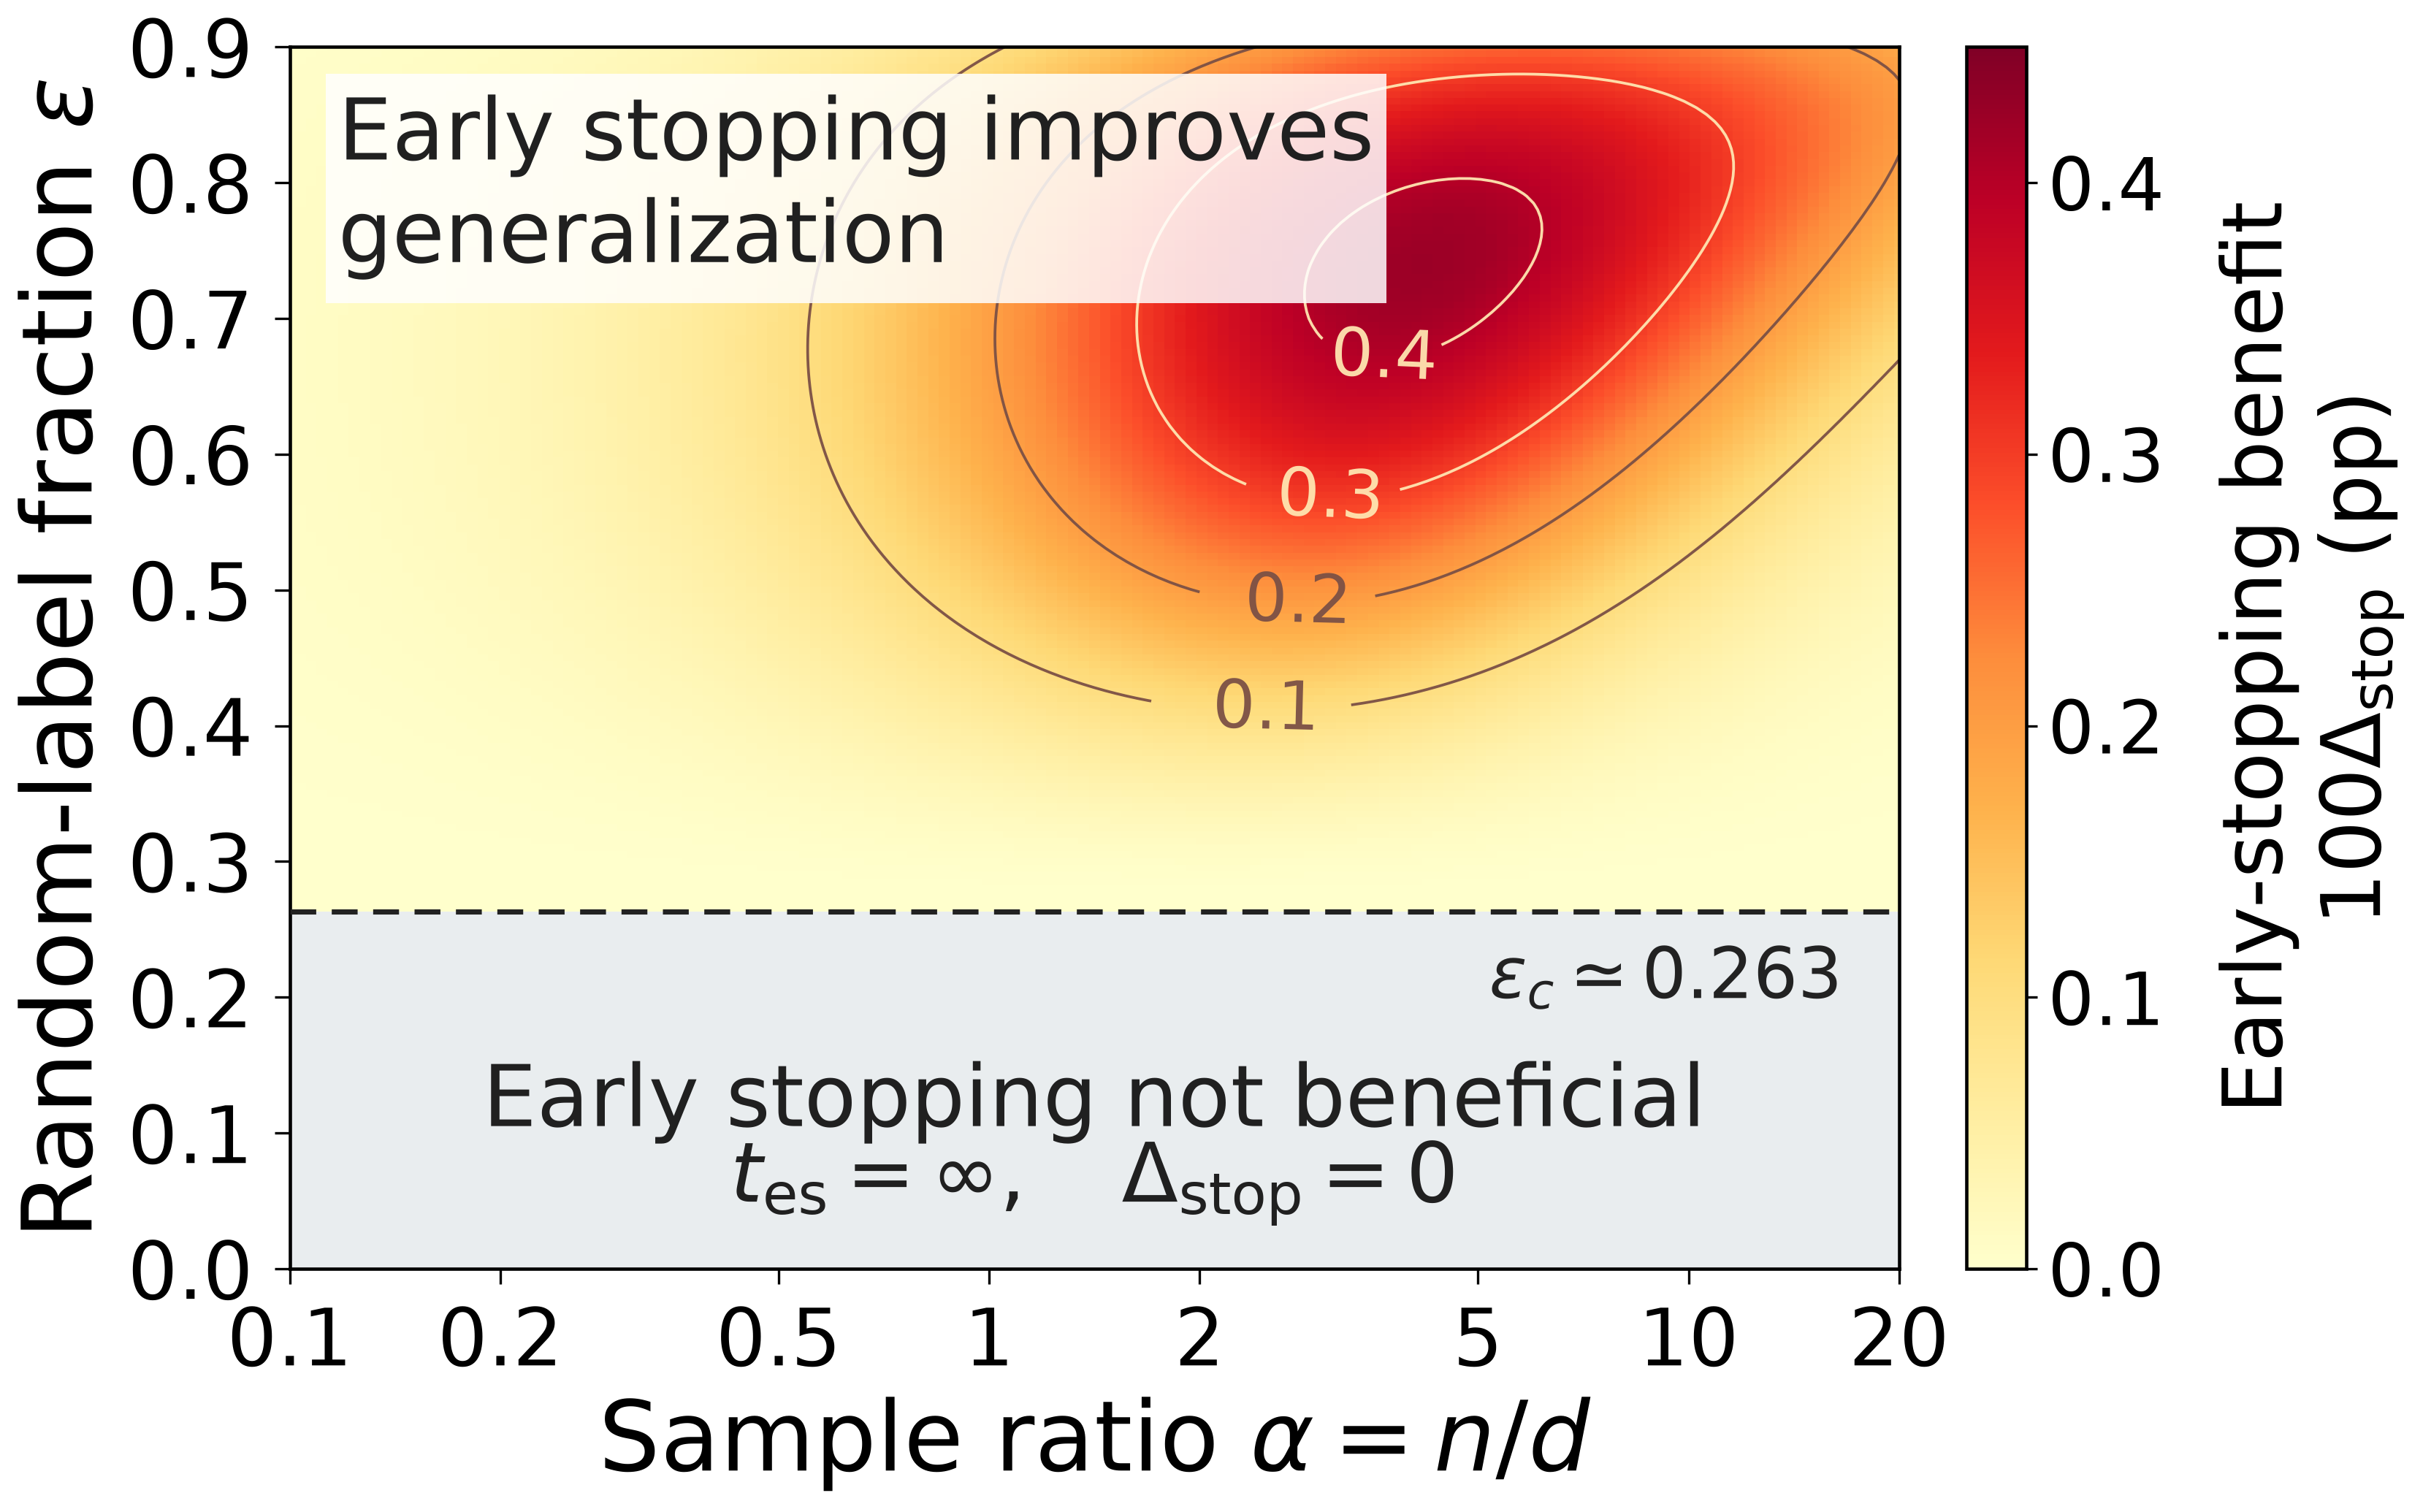

In [6]:
def cell_edges(values, logarithmic=False):
    values = np.asarray(values)
    z = np.log(values) if logarithmic else values
    midpoints = (z[:-1]+z[1:])/2
    
    edges = np.r_[z[0], midpoints, z[-1]]
    return np.exp(edges) if logarithmic else edges

def plot_phase_map(phase, out=OUT):
    out=Path(out)
    out.mkdir(parents=True, exist_ok=True)
    style = {
        'font.family':'DejaVu Sans', 'mathtext.fontset':'dejavusans',
        'font.size':26, 'axes.labelsize':32, 'xtick.labelsize':26,
        'ytick.labelsize':26, 'axes.linewidth':1.1,
        'pdf.fonttype':42, 'ps.fonttype':42, 'savefig.facecolor':'white',
    }
    with plt.rc_context(style):
        fig, ax=plt.subplots(figsize=(10.2,6.8))
        fig.subplots_adjust(left=.12,right=.84,bottom=.14,top=.96)
        ax.set_facecolor('#e9edef')
        above=EPSILONS>EPSILON_C
        plot_noise=np.r_[EPSILON_C, EPSILONS[above]]
        plot_gap=np.vstack([np.zeros(len(ALPHAS)),100*phase['delta_stop'][above]])
        assert plot_gap.max() <= .45, 'Expand the color scale for these parameters'
        scale=Normalize(vmin=0.,vmax=.45)
        mesh=ax.pcolormesh(cell_edges(ALPHAS,True),cell_edges(plot_noise),
                           plot_gap,cmap='YlOrRd',norm=scale,
                           shading='flat',rasterized=True)
        contours=ax.contour(ALPHAS,plot_noise,plot_gap,
                            levels=[.1,.2,.3,.4],
                            colors=['#7b5045','#7b5045','#ffe6b1','#ffe6b1'],
                            linewidths=.9,alpha=.95)
        anchors=[]
        for segments in contours.allsegs:
            segment=max(segments,key=len)
            anchors.append(tuple(segment[np.argmin(segment[:,1])]))
        ax.clabel(contours,fmt='%.1f',fontsize=22,inline=True,manual=anchors)
        ax.axhline(EPSILON_C,color='#222222',lw=1.7,ls=(0,(5,3)),zorder=5)
        ax.text(.03,.968,'Early stopping improves\ngeneralization',
                transform=ax.transAxes,ha='left',va='top',fontsize=28,
                color='#202020',bbox=dict(facecolor='white',alpha=.85,edgecolor='none',pad=4))
        ax.text(.5,.135,'Early stopping not beneficial',
                transform=ax.transAxes,ha='center',va='center',fontsize=28,color='#202020')
        ax.text(.5,.070,r'$t_{\rm es}=\infty,\quad\Delta_{\rm stop}=0$',
                transform=ax.transAxes,ha='center',va='center',fontsize=27,color='#202020')
        ax.text(.965,EPSILON_C/.9-.028,rf'$\varepsilon_c\simeq{EPSILON_C:.3f}$',
                transform=ax.transAxes,ha='right',va='top',fontsize=23,color='#222222')
        ax.set(xscale='log',xlim=(ALPHAS[0],ALPHAS[-1]),ylim=(0,.9),
               xlabel=r'Sample ratio $\alpha=n/d$',ylabel=r'Random-label fraction $\varepsilon$')
        ticks=[.1,.2,.5,1,2,5,10,20]
        ax.xaxis.set_major_locator(FixedLocator(ticks))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{x:g}'))
        ax.set_yticks(np.arange(0,1,.1))
        ax.tick_params(which='major',length=5,pad=7)
        ax.tick_params(which='minor',bottom=False,left=False)
        cax=fig.add_axes([.87,.14,.027,.82])
        bar=fig.colorbar(mesh,cax=cax,ticks=np.arange(0,.451,.1))
        bar.set_label('Early-stopping benefit\n' + r'$100\Delta_{\rm stop}$ (pp)',fontsize=27,labelpad=15)
        bar.ax.tick_params(labelsize=24)
        for suffix in ('pdf','png'):
            fig.savefig(out/f'Figure2_phase_diagram.{suffix}',
                        dpi=300,bbox_inches='tight',pad_inches=.08)
        plt.close(fig)
    print('Saved PDF:',out/'Figure2_phase_diagram.pdf')
    print('Saved PNG:',out/'Figure2_phase_diagram.png')

plot_phase_map(phase)
np.savez_compressed(OUT/'Figure2_phase_diagram_data.npz',
    alpha=ALPHAS,epsilon=EPSILONS,gamma=GAMMA,delta0=DELTA0,ridge=RIDGE,
    epsilon_c=EPSILON_C,**phase)
protocol=dict(flow='RKHS',reduced_time='tau = mu_1^2 t',
    inputs='uniform on the sphere of radius sqrt(d); n/d -> alpha',
    gamma=float(GAMMA),gamma_over_pi=float(GAMMA/np.pi),
    delta0=DELTA0,ridge=RIDGE,epsilon_c=float(EPSILON_C),
    alpha_range=[float(ALPHAS[0]),float(ALPHAS[-1])],
    epsilon_range=[float(EPSILONS[0]),float(EPSILONS[-1])],
    n_alpha=len(ALPHAS),n_epsilon=len(EPSILONS),quadrature_nodes=N_QUAD,
    search_grid_points=N_TIME,color_units='percentage points, linear scale',
    color_limits_pp=[0.,.45],smoothing=False,
    maximum_sampled_benefit_pp=float(100*phase['delta_stop'][maximum_index]),
    maximum_sampled_at=dict(alpha=float(peak_alpha),epsilon=float(peak_epsilon)),
    checks=checks,versions=dict(python=platform.python_version(),numpy=np.__version__,
                               scipy=scipy.__version__,matplotlib=matplotlib.__version__))
(OUT/'Figure2_phase_diagram_protocol.json').write_text(json.dumps(protocol,indent=2)+'\n')
print('Saved arrays and numerical-check protocol.')

display(Image(filename=str(OUT/'Figure2_phase_diagram.png')))


## Shared learning-curve equations for Figures 3 and 4

`curves` evaluates the test overlaps $m,q$, the factual-margin mean and variance $V,Q$, the two classification errors, and the training square loss. `stopping_time` solves $2m' q-mq'=0$ on the finite-stopping side and returns infinity on the convergence side. These are analytical high-dimensional learning curves, evaluated by spectral quadrature rather than finite-sample simulations.


In [7]:
@dataclass(frozen=True)
class Case:
    name: str
    alpha: float
    epsilon: float
    b: float
    delta0: float = 0.0
    def __post_init__(self):
        if not (self.alpha > 0 and 0 <= self.epsilon < 1 and self.b > 0 and self.delta0 >= 0):
            raise ValueError("Require alpha>0, 0<=epsilon<1, b>0 and delta0>=0.")
    @property
    def a(self): return (1-self.epsilon)*np.sqrt(2/np.pi)
    @property
    def bc(self): return 1/self.a**2-1
    @property
    def gamma_pi(self): return np.arctan(1/np.sqrt(self.b))/np.pi

@lru_cache(maxsize=256)
def quadrature(alpha, n=NQUAD):
    """Positive MP eigenvalues; weights for feature/sample normalization and zero atom."""
    theta = (np.arange(n)+0.5)*np.pi/n
    s = (np.sqrt(alpha)-1)**2+4*np.sqrt(alpha)*np.sin(theta/2)**2
    wn = 2*alpha*np.sin(theta)**2/(n*s)
    wr = wn/alpha
    atom = max(1-1/alpha, 0.0)
    return s, wn, wr, atom

def errors_from_moments(m, q, V, Q):
    corr = np.divide(m, np.sqrt(np.maximum(q, 0)), out=np.zeros_like(m), where=q>0)
    gen = np.arccos(np.clip(corr, -1, 1))/np.pi
    mem = np.full_like(gen, 0.5)
    mask = Q>0
    mem[mask] = 0.5*erfc(V[mask]/np.sqrt(2*Q[mask]))
    mem[(~mask)&(V>0)] = 0.0
    return gen, mem

def curves(c, times, ell=0.0, n=NQUAD, chunk=96):
    """Evaluate the paper's m, q, V, Q equations and the resulting errors/loss."""
    t = np.atleast_1d(np.asarray(times, dtype=float))
    if np.any(t<0) or np.any(np.isnan(t)) or not (np.isfinite(ell) and ell>=0):
        raise ValueError("Nonnegative times and finite nonnegative ell required.")
    s, wn, wr, atom = quadrature(c.alpha, n)
    a, b = c.a, c.b
    rate = s+b+ell
    W = 1-a*a+a*a*s
    names = ("m", "q", "V", "Q", "E_gen", "E_mem", "L_train")
    result = {k: np.empty(len(t)) for k in names}
    for lo in range(0, len(t), chunk):
        sl = slice(lo, min(lo+chunk, len(t)))
        r = np.exp(-t[sl,None]*rate)
        H = -np.expm1(-t[sl,None]*rate)
        F = s/rate*H
        h = (s+b)/rate*H
        r0 = np.exp(-t[sl]*(b+ell))
        h0 = b/(b+ell)*(-np.expm1(-t[sl]*(b+ell)))
        m = a*(F@wn)
        q = ((a*a+(1-a*a)/s)*F*F)@wn+c.delta0*((s*r*r)@wn)
        V = h@wr+atom*h0
        Q = (W*(h-V[:,None])**2)@wr+(1-a*a)*atom*(h0-V)**2
        Q += c.delta0*(((s+b)**2*r*r)@wr+atom*b*b*r0*r0)
        loss = 0.5*((W*(1-h)**2+c.delta0*(s+b)**2*r*r)@wr
            +atom*((1-a*a)*(1-h0)**2+c.delta0*b*b*r0*r0))
        gen, mem = errors_from_moments(m, q, V, Q)
        for key, value in zip(names, (m,q,V,Q,gen,mem,loss)): result[key][sl]=value
    return {"tau": t, "ell": float(ell), **result}

def right_limit(c):
    
    if c.delta0>0: return 0.5, 0.5
    gen = np.arccos(c.a*np.sqrt(c.alpha)/np.sqrt(1+c.a*c.a*c.alpha))/np.pi
    mem = 0.5*erfc((1+c.b)/np.sqrt(2*c.alpha*(1+c.a*c.a*c.alpha)))
    return float(gen), float(mem)

def global_error(alpha, epsilon, n=NQUAD):
    a = (1-epsilon)*np.sqrt(2/np.pi)
    bc = 1/a**2-1
    s, wn, _, _ = quadrature(alpha,n)
    return float(np.arccos(np.sqrt((s/(s+bc))@wn))/np.pi)

def stationarity(c, t, n=NQUAD):
    
    
    s, wn, _, _ = quadrature(c.alpha, n)
    rate = s+c.b
    r = np.exp(-t*rate)
    h = -np.expm1(-t*rate)
    p = s/rate
    W = s*(c.a*c.a*s+1-c.a*c.a)/rate**2
    M = (p*h)@wn
    q = (W*h*h)@wn+c.delta0*((s*r*r)@wn)
    if c.delta0==0 and t*rate.max()<0.05:
        L = -rate/2+t*rate**2/12-t**3*rate**4/720+t**5*rate**6/30240
        Mp = ((p*h)*L)@wn
        qp = 2*((W*h*h)*L)@wn
    else:
        rs = np.exp(-t*(rate-rate.min()))
        Mp = (p*rate*rs)@wn
        qp = 2*((W*h*rate*rs)@wn)-2*c.delta0*((s*rate*r*rs)@wn)
    return float(2*Mp*q-M*qp)

def stopping_time(c, n=NQUAD):
    if c.b>=c.bc or np.isclose(c.b,c.bc,rtol=2e-13,atol=0): return np.inf
    s, *_ = quadrature(c.alpha,n)
    grid = np.geomspace(1e-9/(s.max()+c.b),max(80/(s.min()+c.b),1),420)
    signs = np.array([stationarity(c,t,n) for t in grid])
    idx = np.flatnonzero((signs[:-1]>0)&(signs[1:]<0))
    candidates = [brentq(lambda t:stationarity(c,t,n),grid[i],grid[i+1],xtol=1e-12) for i in idx]
    if not candidates: raise ArithmeticError("No finite optimum bracketed.")
    return float(candidates[int(np.argmin(curves(c,candidates,n=n)["E_gen"]))])

def ridge_path(c, ells, n=NQUAD):
    
    values = [curves(c,[np.inf],ell=float(ell),n=n) for ell in ells]
    return {"ell":np.asarray(ells), **{key:np.array([v[key][0] for v in values])
            for key in ("m","q","V","Q","E_gen","E_mem","L_train")}}


for alpha in (0.2,0.85,1.0,1.5,8.0):
    s,wn,wr,atom=quadrature(alpha)
    assert abs(wr.sum()+atom-1)<2e-11
    assert abs(s@wr-1)<2e-11
    assert abs((s*s)@wr-(1+alpha))<2e-10
print("Marchenko–Pastur mass, first moment, second moment and zero-atom checks passed.")


Marchenko–Pastur mass, first moment, second moment and zero-atom checks passed.


## Figure 3: interpolation and stopping across kernel angles

We fix $\alpha=1.5$, $\varepsilon=0.1$, and $\lambda=0$, and compare initializations $\delta_0=0$ and $1$. The inset plots the zero-initialized stopping error above the critical test error, with the same $\gamma/\pi$ horizontal coordinate.


Saved: Figures/kernel_angle_initializations-4.pdf
Saved: Figures/kernel_angle_initializations-4.png


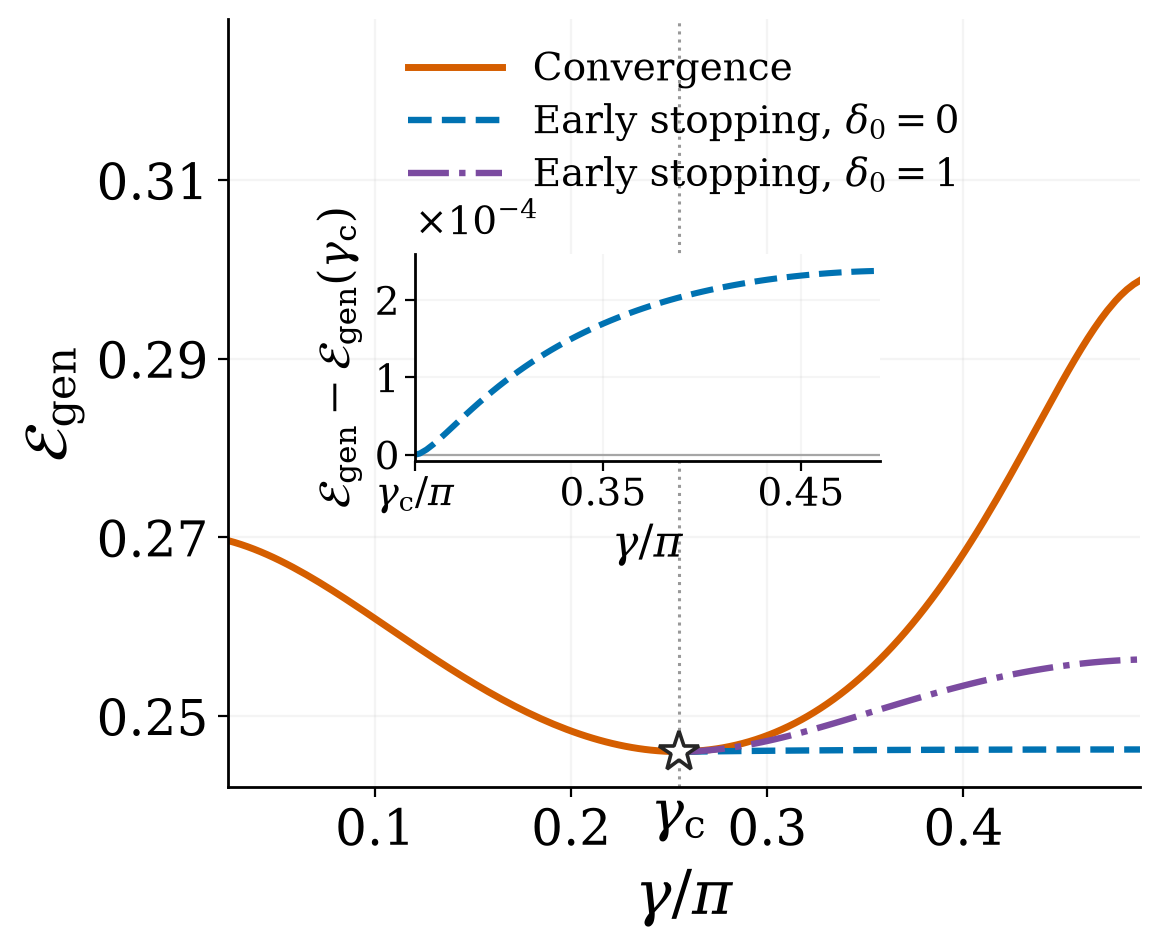

In [8]:


with threadpool_limits(limits=1):
    ANGLE_ALPHA,ANGLE_EPSILON=1.5,.1
    angle_bc=1/((1-ANGLE_EPSILON)**2*2/np.pi)-1
    angle_critical=np.arctan(1/np.sqrt(angle_bc))
    angle_values=np.unique(np.r_[np.linspace(.025*np.pi,.49*np.pi,141),angle_critical,
        np.arctan(1/np.sqrt(.005)),np.arctan(1/np.sqrt(100.))])
    angle_endpoint=[]
    angle_optimal={0.:[],1.:[]}
    angle_times={0.:[],1.:[]}
    for gamma in angle_values:
        b=float(1/np.tan(gamma)**2)
        for delta0 in (0.,1.):
            c=Case("angle",ANGLE_ALPHA,ANGLE_EPSILON,b,delta0)
            t=stopping_time(c,n=800)
            val=curves(c,[t,np.inf],n=NQUAD)["E_gen"]
            angle_times[delta0].append(t)
            angle_optimal[delta0].append(val[0])
            if delta0==0: angle_endpoint.append(val[1])
    angle_endpoint=np.asarray(angle_endpoint)
    for delta0 in (0.,1.):
        angle_times[delta0]=np.asarray(angle_times[delta0])
        angle_optimal[delta0]=np.asarray(angle_optimal[delta0])
    angle_bound=global_error(ANGLE_ALPHA,ANGLE_EPSILON)
    finite=angle_values>angle_critical+1e-12
    assert np.all(angle_optimal[1.]>=angle_optimal[0.]-1e-12)
    for delta0 in (0.,1.):
        assert np.all(angle_optimal[delta0]>=angle_bound-1e-12)
        assert np.all(angle_optimal[delta0]<=angle_endpoint+1e-12)
        assert np.allclose(angle_optimal[delta0][~finite],angle_endpoint[~finite],atol=1e-12,rtol=0)
        assert np.all(angle_optimal[delta0][finite]>angle_bound)
    
    angle_examples=[]
    for delta0 in (0.,1.):
        c=Case("Figure 4 angle",ANGLE_ALPHA,ANGLE_EPSILON,.005,delta0)
        t=stopping_time(c,n=3200)
        v=curves(c,[t,np.inf],n=3200)
        angle_examples.append(dict(delta0=delta0,b=c.b,gamma_pi=c.gamma_pi,tau_es=t,
            E_gen_es=float(v["E_gen"][0]),E_mem_es=float(v["E_mem"][0]),
            E_gen_endpoint=float(v["E_gen"][1]),excess_pp=float(100*(v["E_gen"][0]-angle_bound))))

def plot_angle_initializations():
    with plt.rc_context(PLOT_STYLE):
        fig,ax=plt.subplots(figsize=(5.7,4.8))
        ax.plot(angle_values/np.pi,angle_endpoint,color=COLORS[1],lw=2.5,label='Convergence')
        for delta0,color,ls in ((0.,COLORS[0],'--'),(1.,'#7B4BA0','-.')):
            ax.plot(angle_values[finite]/np.pi,angle_optimal[delta0][finite],
                    color=color,lw=2.3,ls=ls,label=rf'Early stopping, $\delta_0={delta0:g}$')
        ax.axvline(angle_critical/np.pi,color='.6',ls=':',lw=1.1)
        ax.plot(angle_critical/np.pi,angle_bound,'*',ms=15,
                mfc='white',mec='.15',mew=1.3,zorder=5)
        ax.annotate(r'$\gamma_{\rm c}$', xy=(angle_critical/np.pi,angle_bound),
                    xytext=(0,-13),textcoords='offset points',ha='center',va='top',
                    fontsize=20,annotation_clip=False,zorder=6)
        ax.set(xlabel=r'$\gamma/\pi$',ylabel=r'$\mathcal{E}_{\rm gen}$',
               xlim=(.025,.49),ylim=(angle_bound-.004,.328))
        ax.xaxis.label.set_size(22)
        ax.yaxis.label.set_size(22)
        ax.tick_params(labelsize=18)
        ax.set_xticks([.1,.2,.3,.4])
        ax.set_yticks([.25,.27,.29,.31])
        ax.legend(loc='upper center',frameon=False,fontsize=14,
                  handlelength=2.4,borderpad=.3,labelspacing=.35)
        ax.grid(alpha=.13)
        
        iax=ax.inset_axes([.205,.425,.51,.27])
        gamma_inset=np.r_[angle_critical,angle_values[finite]]/np.pi
        gap=np.r_[0.,angle_optimal[0.][finite]-angle_bound]
        iax.axhline(0.,color='.65',lw=.8)
        iax.plot(gamma_inset,1e4*gap,color=COLORS[0],ls='--',lw=2.2)
        iax.set(xlim=(angle_critical/np.pi,.49),ylim=(-.08,2.6))
        iax.set_xticks([angle_critical/np.pi,.35,.45])
        iax.set_xticklabels([r'$\gamma_{\rm c}/\pi$','0.35','0.45'])
        iax.set_yticks([0.,1.,2.])
        iax.set_xlabel(r'$\gamma/\pi$',fontsize=16,labelpad=3)
        iax.set_ylabel(r'$\mathcal{E}_{\rm gen}-\mathcal{E}_{\rm gen}(\gamma_{\rm c})$',
                       fontsize=16,labelpad=4,color='black')
        iax.tick_params(labelsize=14,length=3.5,pad=2)
        iax.tick_params(axis='y',labelcolor='black')
        iax.text(0.,1.045,r'$\times10^{-4}$',transform=iax.transAxes,
                 fontsize=14,color='black',ha='left',va='bottom')
        iax.grid(alpha=.12)
        fig.subplots_adjust(left=.17,right=.97,bottom=.17,top=.97)
        save_figure(fig,'kernel_angle_initializations-4')

plot_angle_initializations()
np.savez_compressed(OUT/'kernel_angle_initializations-4_data.npz',gamma=angle_values,
    endpoint_error=angle_endpoint,optimal_error_delta0=angle_optimal[0.],
    optimal_error_delta1=angle_optimal[1.],tau_es_delta0=angle_times[0.],
    tau_es_delta1=angle_times[1.],gamma_c=angle_critical,error_bound=angle_bound,
    alpha=ANGLE_ALPHA,epsilon=ANGLE_EPSILON)
save_json('kernel_angle_initializations-4_parameters.json',dict(alpha=ANGLE_ALPHA,
    epsilon=ANGLE_EPSILON,delta0=[0,1],ell=0,nquad=NQUAD,
    gamma_c_pi=angle_critical/np.pi,error_bound=angle_bound,
    inset='Zero-initialized optimal test error minus critical bound, for gamma>=gamma_c; '
          'horizontal axis is gamma/pi, starting at gamma_c/pi; '
          'vertical axis is E_gen_opt(gamma)-E_gen_infinity(gamma_c), in units of 1e-4',examples=angle_examples))
display(Image(filename=str(OUT/'kernel_angle_initializations-4.png')))


## Figure 4: complete gradient-flow paths

We fix $\alpha=1.5$, $\varepsilon=0.1$, $\delta_0=1$, and $\lambda=0$. The three shifts are exactly $b=0.005$, $b=b_c$, and $b=100$, giving $\gamma/\pi\simeq0.477529,0.254986,0.031726$. The rounded legend matches the current paper. All trajectories include the analytical $t\to0^+$ limit $(\mathcal E_{\rm gen},\mathcal E_{\rm mem})=(0.5,0.5)$ and the exact converged endpoint. Green is used for the small-angle curve.


Saved: Figures/Figure_GF_span_large_fonts-2.pdf
gamma/pi: 0.477529493, 0.254986190, 0.031725517


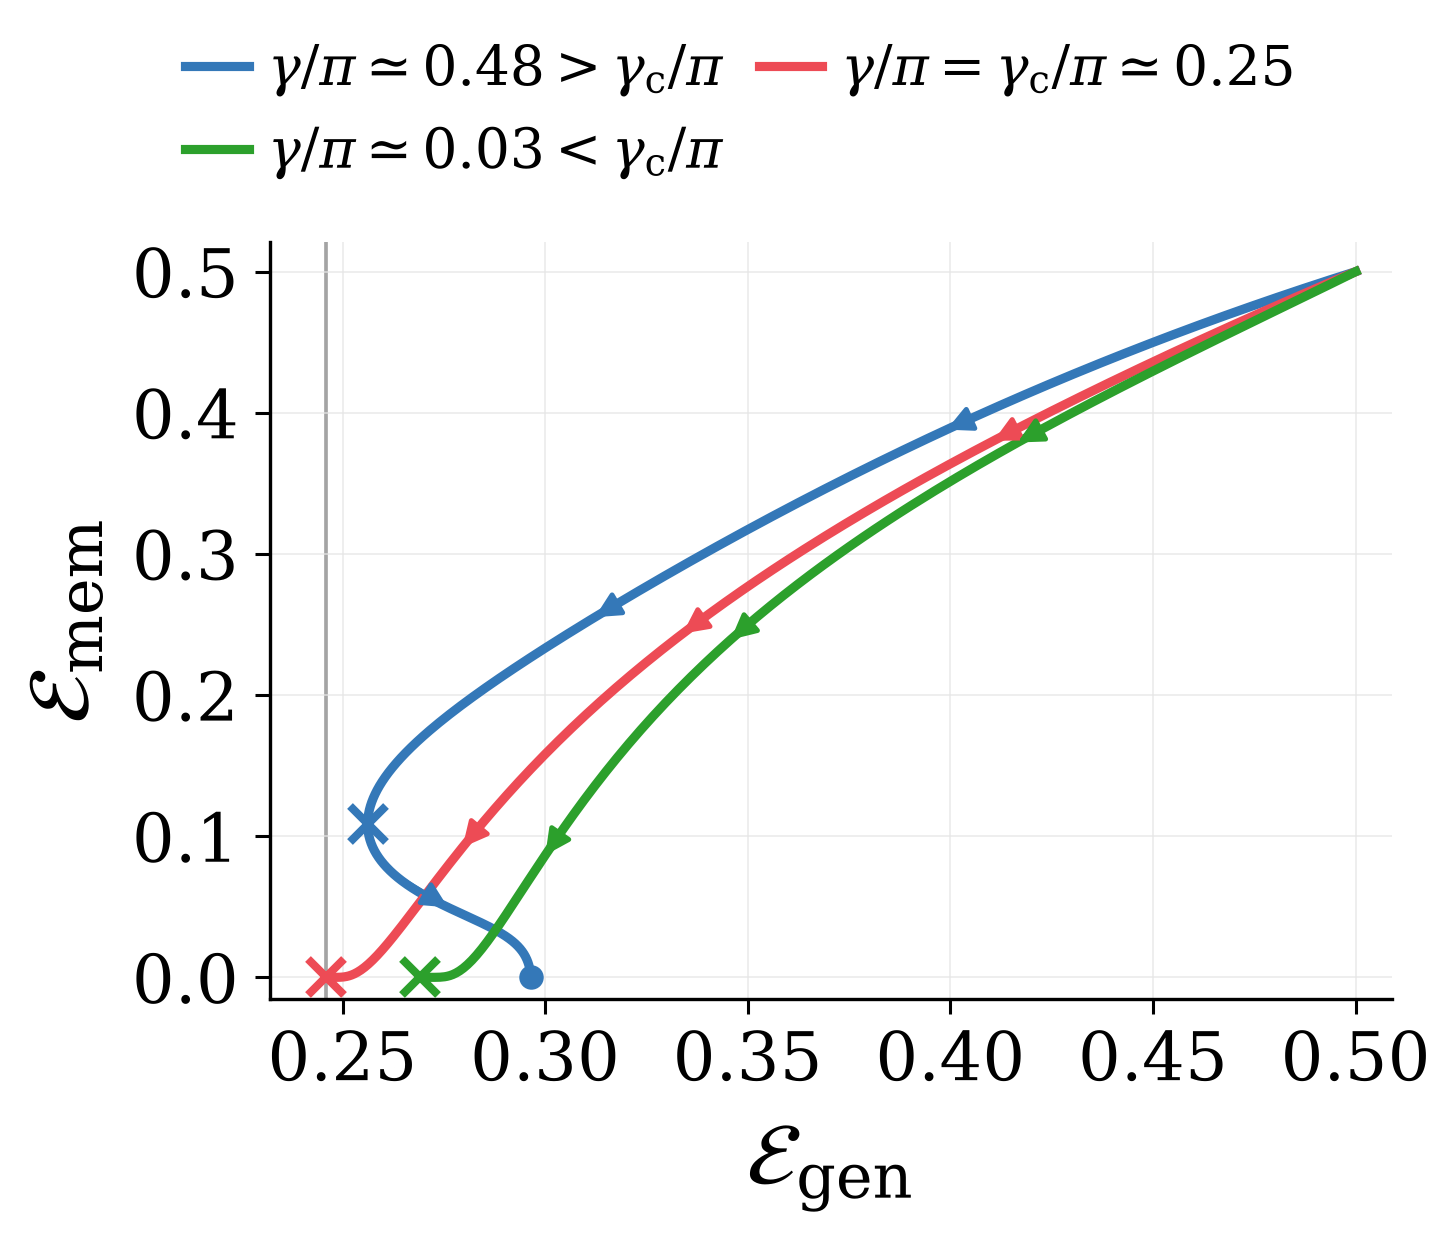

In [9]:

ALPHA,EPSILON,DELTA0=1.5,0.1,1.0
NQUAD=1600
BC=np.pi/(2*(1-EPSILON)**2)-1
SHIFTS=(.005,BC,100.)
COLORS=("#3478B8","#ED4B55","#2CA02C")
STYLE={"font.family":"serif","font.size":21,"mathtext.fontset":"dejavuserif",
       "axes.labelsize":29,"xtick.labelsize":22,"ytick.labelsize":22,
       "axes.linewidth":1.1,"axes.spines.top":False,"axes.spines.right":False,
       "pdf.fonttype":42,"ps.fonttype":42,"text.usetex":False}


cases=[Case(name,ALPHA,EPSILON,b,DELTA0) for name,b in zip(
    ("Finite stopping","Critical angle","Convergence optimum"),SHIFTS)]
path_bound=global_error(ALPHA,EPSILON)
records=[]
for case in cases:
    s,*_=quadrature(case.alpha)
    tau_es=stopping_time(case)
    tau=np.geomspace(1e-8/(s.max()+case.b),80/case.b,2600)
    if np.isfinite(tau_es):tau=np.unique(np.r_[tau,tau_es])
    tau=np.r_[0.,tau,np.inf]
    gf=curves(case,tau)
    best=curves(case,[tau_es])
    assert gf['E_gen'][0]==gf['E_mem'][0]==.5
    assert gf['E_mem'][-1]==0.
    assert abs(best['E_gen'][0]-gf['E_gen'].min())<1e-9
    records.append((case,tau_es,gf,best))

def path_arrow(ax, x, y, color, fraction=.65, span=.06, visible_only=False):
    
    x, y = np.asarray(x), np.asarray(y)
    if visible_only:
        visible = ((x >= ax.get_xlim()[0]) & (x <= ax.get_xlim()[1]) &
                   (y >= ax.get_ylim()[0]) & (y <= ax.get_ylim()[1]))
        
        indices = np.flatnonzero(visible)
        if len(indices) < 2:
            return
        runs = np.split(indices, np.flatnonzero(np.diff(indices) != 1) + 1)
        indices = max(runs, key=len)
        x, y = x[indices], y[indices]
    xscale, yscale = np.diff(ax.get_xlim())[0], np.diff(ax.get_ylim())[0]
    length = np.r_[0., np.cumsum(np.hypot(np.diff(x) / xscale,
                                         np.diff(y) / yscale))]
    if length[-1] < .06:
        return
    lo = np.searchsorted(length, max(0., fraction - span / 2) * length[-1])
    hi = min(np.searchsorted(length, min(1., fraction + span / 2) * length[-1]),
             len(x) - 1)
    if hi > lo:
        ax.annotate('', xy=(x[hi], y[hi]), xytext=(x[lo], y[lo]),
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=1.6,
                                    mutation_scale=17, shrinkA=0, shrinkB=0),
                    zorder=7)

with plt.rc_context(STYLE):
    fig,ax=plt.subplots(figsize=(6.3,5.25))
    ax.set(xlim=(.232,.509),ylim=(-.015,.521),
           xlabel=r'$\mathcal{E}_{\rm gen}$',ylabel=r'$\mathcal{E}_{\rm mem}$')
    ax.axvline(path_bound,color='.35',lw=1.2,alpha=.55,zorder=0)
    ax.grid(color='.90',lw=.65,alpha=.65)
    labels=(r'$\gamma/\pi\simeq0.48>\gamma_{\rm c}/\pi$',
            r'$\gamma/\pi=\gamma_{\rm c}/\pi\simeq0.25$',
            r'$\gamma/\pi\simeq0.03<\gamma_{\rm c}/\pi$')
    for (case,tau_es,gf,best),color,label in zip(records,COLORS,labels):
        ax.plot(gf['E_gen'],gf['E_mem'],color=color,lw=3,label=label,zorder=3)
        for fraction in ((.27,.55,.89) if np.isfinite(tau_es) else (.27,.55,.81)):
            path_arrow(ax,gf['E_gen'],gf['E_mem'],color,fraction,span=.045,visible_only=True)
        ax.plot(best['E_gen'][0],best['E_mem'][0],'x',color=color,
                ms=11.5,mew=2.65,zorder=9,clip_on=False)
        if np.isfinite(tau_es):
            ax.plot(gf['E_gen'][-1],gf['E_mem'][-1],'o',color=color,
                    ms=7,zorder=8,clip_on=False)
    ax.set_xticks([.25,.30,.35,.40,.45,.50])
    ax.set_yticks([0,.1,.2,.3,.4,.5])
    ax.tick_params(length=5,width=1,pad=5)
    ax.xaxis.labelpad=7;ax.yaxis.labelpad=7
    handles,legend_labels=ax.get_legend_handles_labels()
    order=(0,2,1)  
    fig.legend([handles[i] for i in order],[legend_labels[i] for i in order],
               loc='upper center',ncol=2,
               bbox_to_anchor=(.51,1.015),frameon=False,fontsize=18,
               handlelength=1.15,handletextpad=.35,columnspacing=.65)
    fig.subplots_adjust(left=.17,right=.98,bottom=.145,top=.80)
    for ext in ('pdf','png'):
        fig.savefig(OUT/f'Figure_GF_span_large_fonts-2.{ext}',
                    dpi=220,bbox_inches='tight',facecolor='white')
    plt.close(fig)
print('Saved:',OUT/'Figure_GF_span_large_fonts-2.pdf')
print('gamma/pi: '+', '.join(f'{c.gamma_pi:.9f}' for c,_,_,_ in records))

gf_arrays = {}
gf_parameters = []
for index, (case, tau_es, gf, best) in enumerate(records):
    for key, value in gf.items():
        gf_arrays[f'kernel_{index}_{key}'] = value
    gf_parameters.append(dict(case=asdict(case), gamma_pi=case.gamma_pi,
                              tau_es=tau_es, best={key:float(value[0])
                              for key,value in best.items() if isinstance(value,np.ndarray)}))
np.savez_compressed(OUT/'Figure_GF_span_large_fonts-2_data.npz', **gf_arrays)
save_json('Figure_GF_span_large_fonts-2_parameters.json',
          dict(alpha=ALPHA, epsilon=EPSILON, delta0=DELTA0, ridge=0,
               metric='RKHS', nquad=NQUAD, kernels=gf_parameters))
display(Image(filename=str(OUT/'Figure_GF_span_large_fonts-2.png')))


In [10]:
# Refinement of the Figure 3 stopping errors and Figure 4 trajectories.
main_curve_checks = []
for gamma_pi in (0.10, angle_critical/np.pi, 0.26, 0.35, 0.48):
    for delta0 in (0., 1.):
        c = Case('refinement', 1.5, 0.1,
                 float(1/np.tan(np.pi*gamma_pi)**2), delta0)
        low_time, high_time = stopping_time(c, n=1600), stopping_time(c, n=3200)
        low = curves(c, [low_time], n=1600)['E_gen'][0]
        high = curves(c, [high_time], n=3200)['E_gen'][0]
        difference = float(abs(low-high))
        assert difference < 1e-11
        main_curve_checks.append(dict(gamma_pi=gamma_pi, delta0=delta0,
                                      stopping_error_refinement=difference))
for c, _, gf, _ in records:
    sample = np.unique(np.linspace(0, len(gf['tau'])-1, 41).astype(int))
    refined = curves(c, gf['tau'][sample], n=3200)
    difference = max(float(np.max(abs(gf[key][sample]-refined[key])))
                     for key in ('E_gen', 'E_mem'))
    assert difference < 1e-11
    main_curve_checks.append(dict(gamma_pi=c.gamma_pi, delta0=c.delta0,
                                  trajectory_error_refinement=difference))
save_json('main_theory_refinement_checks.json', main_curve_checks)
print('Figure 3 stopping errors and Figure 4 paths pass quadrature refinement.')


Figure 3 stopping errors and Figure 4 paths pass quadrature refinement.


## Figure 5: gradient flow minus ridge at equal memorization error

We fix $\alpha=5$, $\varepsilon=0.1$, and $\delta_0=0$, with $\gamma/\pi=0.40$, $\gamma=\gamma_c$, and $\gamma/\pi=0.22$. For each memorization error we solve separately for gradient-flow time and ridge strength; no interpolation between sampled curves is used. Positive rescaling of each spectral filter improves numerical conditioning without changing either classification error. The one-sided initialization limits and the shared interpolation endpoint are evaluated analytically.


In [11]:
from pathlib import Path
import json
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, MultipleLocator

EPSILON = 0.1
DELTA0 = 0.0
ALPHA, LARGE_GAMMA_PI, SMALL_GAMMA_PI = 5.0, 0.40, 0.22
BC = np.pi / (2*(1-EPSILON)**2) - 1
GAMMA_C_PI = np.arctan(1/np.sqrt(BC))/np.pi
GAMMAS_PI = (LARGE_GAMMA_PI, GAMMA_C_PI, SMALL_GAMMA_PI)
NQUAD = 1600
NPOINTS = 700
OUT = Path("Figures")
OUT.mkdir(parents=True, exist_ok=True)
STEM = "Figure4_GF_minus_Ridge_delta0-2"
print(f"alpha={ALPHA:g}, epsilon={EPSILON:g}, delta0={DELTA0:g}")
print("gamma/pi:", ", ".join(f"{g:.12g}" for g in GAMMAS_PI))
print("NumPy", np.__version__, "SciPy", scipy.__version__, "Matplotlib", matplotlib.__version__)


alpha=5, epsilon=0.1, delta0=0
gamma/pi: 0.4, 0.25498619004, 0.22
NumPy 2.5.4 SciPy 1.18.1 Matplotlib 3.11.2


In [12]:
from functools import lru_cache
import numpy as np
from scipy.special import erfc, erfcinv
from scipy.optimize import brentq

@lru_cache(maxsize=32)
def comparison_mp_quadrature(alpha, order):
    
    theta = (np.arange(order) + 0.5) * np.pi / order
    s = (np.sqrt(alpha) - 1)**2 + 4*np.sqrt(alpha)*np.sin(theta/2)**2
    weight = 2*np.sin(theta)**2 / (order*s)
    atom = max(1 - 1/alpha, 0.)
    if atom > 0:
        s, weight = np.r_[0., s], np.r_[atom, weight]
    return s, weight

class ZeroInitPaths:
    
    def __init__(self, alpha, epsilon, gamma_pi, order=1600, root_xtol=3e-13, root_rtol=1e-14):
        self.alpha, self.epsilon = float(alpha), float(epsilon)
        self.gamma_pi = float(gamma_pi)
        self.b = float(1/np.tan(np.pi*gamma_pi)**2)
        self.a = (1-epsilon)*np.sqrt(2/np.pi)
        self.order = int(order)
        self.root_xtol, self.root_rtol = root_xtol, root_rtol
        self.s, self.w = comparison_mp_quadrature(self.alpha, self.order)
        self.rate = self.s + self.b
        self.W = 1-self.a**2 + self.a**2*self.s
        self.rmax = (1+np.sqrt(alpha))**2+self.b
        self.e0 = float(0.5*erfc((1+self.b)/np.sqrt(2*alpha*(1+self.a**2*alpha))))
        self.g0 = float(np.arccos(self.a*np.sqrt(alpha)/np.sqrt(1+self.a**2*alpha))/np.pi)
        self.ginf = self._from_filter(np.ones_like(self.s))[0]

    def _from_filter(self, h):
        
        
        h = h / np.max(h)
        z = h/self.rate
        m = self.a*self.alpha*np.dot(self.w, self.s*z)
        q = self.alpha*np.dot(self.w, self.s*self.W*z*z)
        V = np.dot(self.w, h)
        Q = np.dot(self.w, self.W*(h-V)**2)
        gen = np.arccos(np.clip(m/np.sqrt(q), -1., 1.))/np.pi
        margin = V/np.sqrt(2*Q) if Q > 0 else np.inf
        return float(gen), float(0.5*erfc(margin)), float(margin)

    def evaluate(self, parameter, family):
        
        if family == 'gf':
            if parameter == 0: return self.g0, self.e0, float(erfcinv(2*self.e0))
            h = -np.expm1(-parameter*self.rate)
        elif family == 'ridge':
            if np.isinf(parameter): return self.g0, self.e0, float(erfcinv(2*self.e0))
            h = self.rate/(self.rate+parameter)
        else:
            raise ValueError("family must be 'gf' or 'ridge'")
        return self._from_filter(h)

    def at_memorization(self, error, family):
        
        if not (0 <= error <= self.e0): raise ValueError('Outside the shared error span.')
        if error == 0:
            return self.ginf, (np.inf if family == 'gf' else 0.), 0.
        if error == self.e0:
            return self.g0, (0. if family == 'gf' else np.inf), self.e0
        target = float(erfcinv(2*error))
        if family == 'gf':
            bracket = (np.log(1e-12/self.rmax), np.log(80/self.b))
        else:
            bracket = (np.log(1e-12*self.b), np.log(1e12*self.rmax))
        def residual(log_parameter):
            return self.evaluate(np.exp(log_parameter), family)[2]-target
        log_parameter = brentq(residual, *bracket, xtol=self.root_xtol, rtol=self.root_rtol)
        parameter = float(np.exp(log_parameter))
        gen, achieved, _ = self.evaluate(parameter, family)
        return gen, parameter, achieved

    def difference_curve(self, points=700):
        
        
        u = .5*(1-np.cos(np.linspace(0,np.pi,points)))
        u = np.unique(np.r_[u, np.geomspace(1e-10,.03,120)])
        e = self.e0*u
        gf = np.asarray([self.at_memorization(v,'gf') for v in e])
        ridge = np.asarray([self.at_memorization(v,'ridge') for v in e])
        return dict(E_mem=e, GF=gf[:,0], Ridge=ridge[:,0],
                    difference=gf[:,0]-ridge[:,0], tau=gf[:,1], ell=ridge[:,1],
                    GF_mem=gf[:,2], Ridge_mem=ridge[:,2], gamma_pi=self.gamma_pi,
                    b=self.b, alpha=self.alpha, epsilon=self.epsilon)


In [13]:
paths = [ZeroInitPaths(ALPHA, EPSILON, g, NQUAD) for g in GAMMAS_PI]
records = [path.difference_curve(NPOINTS) for path in paths]
for record in records:
    residual = max(np.max(np.abs(record["GF_mem"]-record["E_mem"])),
                   np.max(np.abs(record["Ridge_mem"]-record["E_mem"])))
    assert residual < 1e-10
    assert record["difference"][0] == record["difference"][-1] == 0
    print(f"gamma/pi={record['gamma_pi']:.8f}: "
          f"difference in [{record['difference'].min():.6g}, {record['difference'].max():.6g}]")


gamma/pi=0.40000000: difference in [-0.00152756, 0.00153683]
gamma/pi=0.25498619: difference in [-0.00208062, 0]
gamma/pi=0.22000000: difference in [-0.00199822, 0]


In [14]:
for alpha in (0.5, 1.0, ALPHA):
    s, w = comparison_mp_quadrature(alpha, NQUAD)
    assert abs(w.sum()-1) < 2e-11
    assert abs(np.dot(w,s)-1) < 2e-11
    assert abs(np.dot(w,s*s)-(1+alpha)) < 2e-10

verification = []
for path, record in zip(paths, records):
    tau_grid = np.geomspace(1e-8/path.rmax, 40/path.b, 600)
    ell_grid = np.geomspace(1e8*path.rmax, 1e-9*path.b, 600)
    for family, grid in (("gf",tau_grid),("ridge",ell_grid)):
        mem = np.array([path.evaluate(p,family)[1] for p in grid])
        assert np.max(np.diff(mem)) < 1e-12
    refined = ZeroInitPaths(ALPHA, EPSILON, path.gamma_pi, 2*NQUAD)
    samples = np.unique(np.r_[np.linspace(1,len(record["E_mem"])-2,40).astype(int),
                             np.argmax(abs(record["difference"]))])
    max_refinement = 0.
    for i in samples:
        e = record["E_mem"][i]
        hi_gf = refined.at_memorization(e,"gf")[0]
        hi_ridge = refined.at_memorization(e,"ridge")[0]
        max_refinement = max(max_refinement, abs(hi_gf-hi_ridge-record["difference"][i]))
    assert max_refinement < 1e-9
    residual = max(np.max(abs(record["GF_mem"]-record["E_mem"])),
                   np.max(abs(record["Ridge_mem"]-record["E_mem"])))
    verification.append(dict(gamma_pi=path.gamma_pi, matching_residual=float(residual),
                             quadrature_refinement_error=float(max_refinement)))
print("All checks passed: matched memorization, analytical endpoints, monotonic paths and quadrature refinement.")
print("Largest refinement error:", max(v["quadrature_refinement_error"] for v in verification))


class LegendreZeroInitPaths(ZeroInitPaths):
    
    def __init__(self, alpha, epsilon, gamma_pi, order=160):
        super().__init__(alpha, epsilon, gamma_pi, order,
                         root_xtol=1e-14, root_rtol=4*np.finfo(float).eps)
        nodes, weights = roots_legendre(order)
        theta = (nodes+1)*np.pi/2
        self.s = (np.sqrt(alpha)-1)**2+4*np.sqrt(alpha)*np.sin(theta/2)**2
        self.w = weights*np.sin(theta)**2/self.s
        atom = max(1-1/alpha,0.)
        if atom:
            self.s, self.w = np.r_[0.,self.s], np.r_[atom,self.w]
        self.rate = self.s+self.b
        self.W = 1-self.a**2+self.a**2*self.s
        self.ginf = self._from_filter(np.ones_like(self.s))[0]

for index, (path, record) in enumerate(zip(paths, records)):
    alternate = LegendreZeroInitPaths(ALPHA,EPSILON,path.gamma_pi)
    tight = ZeroInitPaths(ALPHA,EPSILON,path.gamma_pi,NQUAD,
                         root_xtol=1e-14,root_rtol=4*np.finfo(float).eps)
    max_alternate = max_tolerance = 0.
    samples = np.unique(np.r_[np.linspace(1,len(record['E_mem'])-2,30).astype(int),
                             np.argmax(abs(record['difference']))])
    for i in samples:
        e = record['E_mem'][i]
        ref = record['difference'][i]
        other = alternate.at_memorization(e,'gf')[0]-alternate.at_memorization(e,'ridge')[0]
        stricter = tight.at_memorization(e,'gf')[0]-tight.at_memorization(e,'ridge')[0]
        max_alternate = max(max_alternate,abs(other-ref))
        max_tolerance = max(max_tolerance,abs(stricter-ref))
    assert max_alternate < 1e-10 and max_tolerance < 1e-10
    assert np.max(abs(record['difference'])) > 1e-4
    verification[index].update(independent_legendre_error=float(max_alternate),
                               tighter_root_error=float(max_tolerance),
                               peak_absolute_signal=float(np.max(abs(record['difference']))))
for result in verification:
    print(result)


All checks passed: matched memorization, analytical endpoints, monotonic paths and quadrature refinement.
Largest refinement error: 7.494005416219807e-16
{'gamma_pi': 0.4, 'matching_residual': 1.6334156249797616e-14, 'quadrature_refinement_error': 4.163336342344337e-16, 'independent_legendre_error': 4.163336342344337e-16, 'tighter_root_error': 2.498001805406602e-16, 'peak_absolute_signal': 0.0015368287989857843}
{'gamma_pi': 0.2549861900395597, 'matching_residual': 1.2961853812498703e-14, 'quadrature_refinement_error': 6.106226635438361e-16, 'independent_legendre_error': 7.216449660063518e-16, 'tighter_root_error': 9.71445146547012e-16, 'peak_absolute_signal': 0.0020806245028249237}
{'gamma_pi': 0.22, 'matching_residual': 1.2101430968414206e-14, 'quadrature_refinement_error': 7.494005416219807e-16, 'independent_legendre_error': 5.828670879282072e-16, 'tighter_root_error': 8.326672684688674e-16, 'peak_absolute_signal': 0.0019982196821053677}


Saved: Figures/Figure4_GF_minus_Ridge_delta0-2.pdf


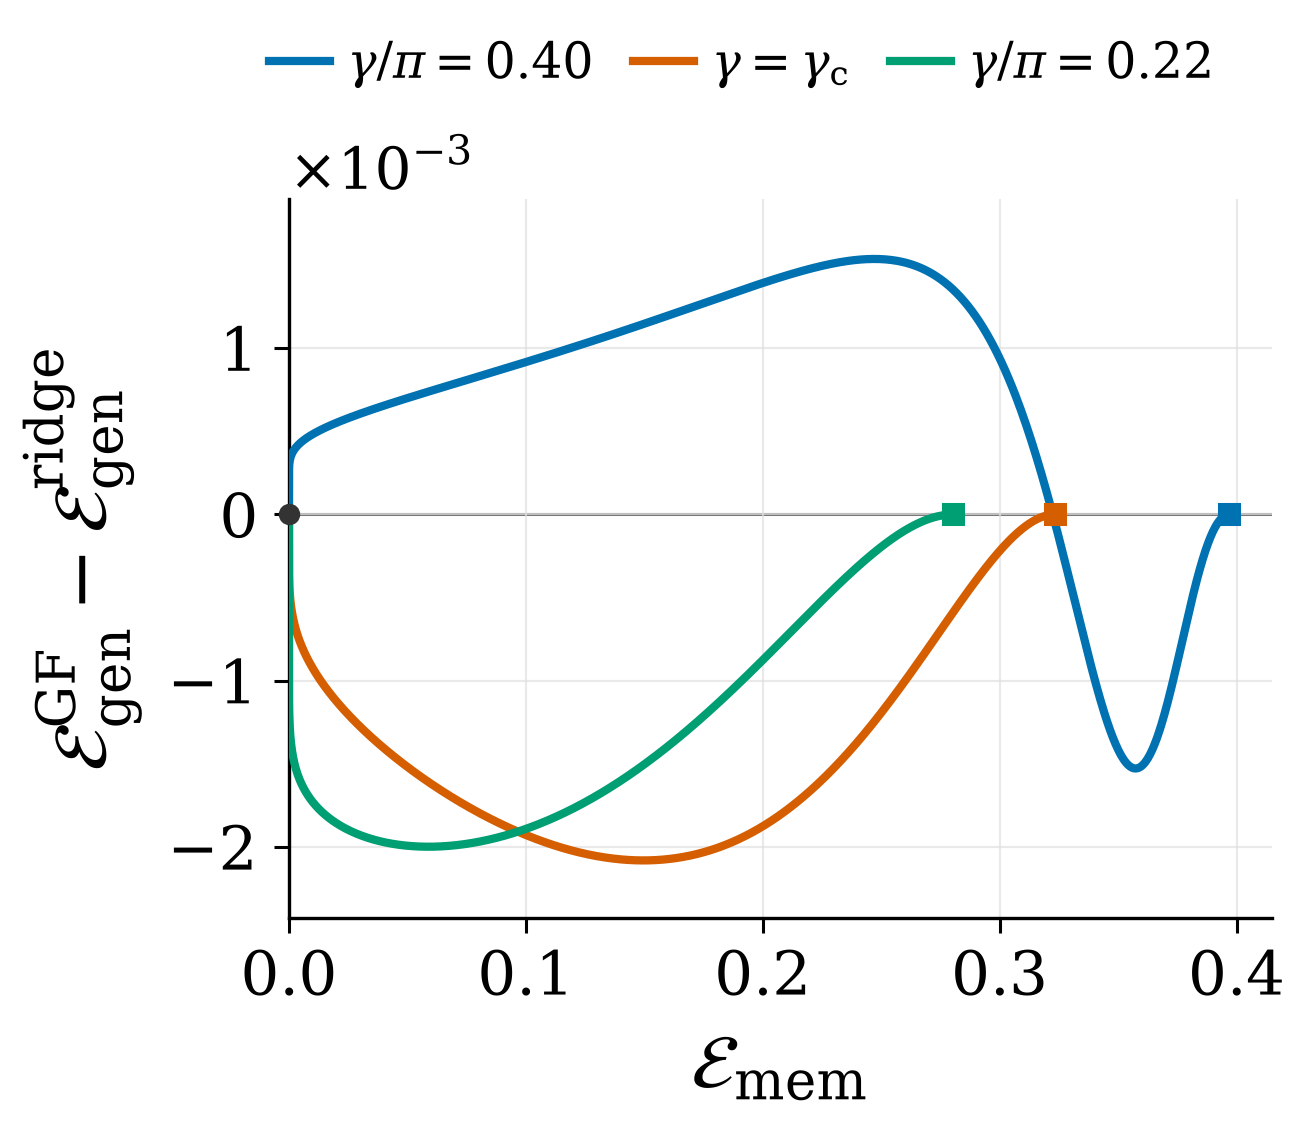

In [15]:
STYLE = {
    "font.family": "serif", "font.size": 20, "mathtext.fontset": "dejavuserif",
    "axes.labelsize": 25, "xtick.labelsize": 20, "ytick.labelsize": 20,
    "axes.linewidth": 1.1, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "text.usetex": False,
}
COLORS = ("#0072B2", "#D55E00", "#009E73")
LABELS = (rf'$\gamma/\pi={GAMMAS_PI[0]:.2f}$', r'$\gamma=\gamma_{\rm c}$',
          rf'$\gamma/\pi={GAMMAS_PI[2]:.2f}$')
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(5.8, 4.95))
    ax.axhline(0, color=".45", lw=1.0, zorder=1)
    for record, color, label in zip(records, COLORS, LABELS):
        ax.plot(record["E_mem"],record["difference"], color=color,
                lw=2.7, label=label, zorder=3)
        ax.plot(record["E_mem"][-1],0,"s",color=color,ms=6.5,zorder=5,clip_on=False)
    ax.plot(0,0,"o",color=".2",ms=6,zorder=6,clip_on=False)
    ax.set_xlabel(r'$\mathcal{E}_{\rm mem}$',labelpad=7)
    ax.set_ylabel(r'$\mathcal{E}_{\rm gen}^{\rm GF}-\mathcal{E}_{\rm gen}^{\rm ridge}$',labelpad=8)
    xmax = max(r["E_mem"][-1] for r in records)
    ymin = min(r["difference"].min() for r in records)
    ymax = max(r["difference"].max() for r in records)
    amplitude = max(ymax-ymin,1e-10)
    ax.set_xlim(0, xmax*1.045)
    ax.set_ylim(ymin-.095*amplitude, ymax+.10*amplitude)
    ax.xaxis.set_major_locator(MultipleLocator(.1))
    ax.yaxis.set_major_locator(MultipleLocator(.001))
    formatter = ScalarFormatter(useMathText=True)
    formatter.set_scientific(True)
    formatter.set_powerlimits((0,0))
    ax.yaxis.set_major_formatter(formatter)
    ax.yaxis.get_offset_text().set_fontsize(19)
    ax.tick_params(which="major",length=5,width=1,pad=5)
    ax.grid(color=".88",lw=.7,alpha=.7)
    fig.legend(*ax.get_legend_handles_labels(),loc="upper center",ncol=3,
               bbox_to_anchor=(.56,1.015),frameon=False,fontsize=16,
               handlelength=1.25,handletextpad=.35,columnspacing=.8)
    fig.subplots_adjust(left=.205,right=.975,bottom=.17,top=.83)
    for extension in ("pdf","png"):
        fig.savefig(OUT/f"{STEM}.{extension}",dpi=220,bbox_inches="tight",facecolor="white")
    plt.close(fig)
print("Saved:",OUT/f"{STEM}.pdf")

display(Image(filename=str(OUT/f"{STEM}.png")))


In [16]:
arrays = {}
for i, record in enumerate(records):
    for key, value in record.items():
        arrays[f"kernel_{i}_{key}"] = value
np.savez_compressed(OUT/f"{STEM}_data.npz",**arrays)
parameters = dict(metric="RKHS",alpha=ALPHA,epsilon=EPSILON,delta0=DELTA0,
                  gf_ridge=0,gamma_pi=list(GAMMAS_PI),gamma_c_pi=GAMMA_C_PI,
                  nquad=NQUAD,comparison="Equal memorization error",checks=verification)
(OUT/f"{STEM}_parameters.json").write_text(json.dumps(parameters,indent=2)+"\n")

1211

In [17]:
expected_pdfs = [
    'Figure2_phase_diagram.pdf',
    'kernel_angle_initializations-4.pdf',
    'Figure_GF_span_large_fonts-2.pdf',
    'Figure4_GF_minus_Ridge_delta0-2.pdf',
]
for name in expected_pdfs:
    path = OUT/name
    assert path.is_file() and path.stat().st_size > 1000, name
print('All four main theory figures were recomputed and saved successfully.')


All four main theory figures were recomputed and saved successfully.
